# MNIST: handwritten digit classification

Experiments with a plain fully connected (dense) network, following the classic Keras examples. Code is unchanged from the original run; only warnings (which contained local file paths) were removed from the saved outputs.

**Experiments:** baseline → ReLU vs. Tanh → MSE vs. cross-entropy loss → number of input words (where applicable) → number of hidden layers → number of neurons.

Results of the number-of-words / layers / neurons experiments are shown as plots only (no numeric summary was printed). Runs are not seeded, so the same configuration gives slightly different numbers in different cells.

**Setup:** flattened 28×28 images, Dense(512, ReLU)-softmax(10), RMSprop, batch size 128, 5 epochs; test = 10,000 test images.

> **Note on validation:** the baseline trains on all 60,000 images. The ReLU/Tanh and MSE/cross-entropy cells use `validation_split=0.2` (training on 48,000 images), so their numbers are not directly comparable with the baseline. The layers and neurons experiments pass the **test set** as `validation_data`, so their validation curves are test curves.


ورژن اصلی MNIST

In [1]:
from keras.datasets import mnist
from keras import models
from keras import layers
from keras.utils import to_categorical

# بارگذاری داده‌ها
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

# پیش‌پردازش تصاویر
train_images = train_images.reshape((60000, 28 * 28))
train_images = train_images.astype('float32') / 255

test_images = test_images.reshape((10000, 28 * 28))
test_images = test_images.astype('float32') / 255

# تبدیل برچسب‌ها به قالب دسته‌بندی‌شده
train_labels = to_categorical(train_labels)
test_labels = to_categorical(test_labels)

# ساخت مدل
network = models.Sequential()
network.add(layers.Dense(512, activation='relu', input_shape=(28 * 28,)))
network.add(layers.Dense(10, activation='softmax'))

# کامپایل مدل
network.compile(optimizer='rmsprop',
                loss='categorical_crossentropy',
                metrics=['accuracy'])

# آموزش مدل
network.fit(train_images, train_labels, epochs=5, batch_size=128)

# ارزیابی مدل
test_loss, test_acc = network.evaluate(test_images, test_labels)
print('test_acc:', test_acc)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 19s 2us/step
Epoch 1/5


469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8708 - loss: 0.4447
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9663 - loss: 0.1171
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9775 - loss: 0.0760
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9854 - loss: 0.0493
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9889 - loss: 0.0370
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9772 - loss: 0.0685
test_acc: 0.9811000227928162


Relu به Tanh  

«🔹 ReLU سریع‌تر یاد می‌گیره ولی ممکنه در بعضی نودها خاموش بشه (Dead Neurons)»

«🟠 Tanh در ابتدای آموزش کندتره ولی خروجی اون محدوده [-1, 1] داره که ممکنه در برخی مدل‌ها مفید باشه.» 

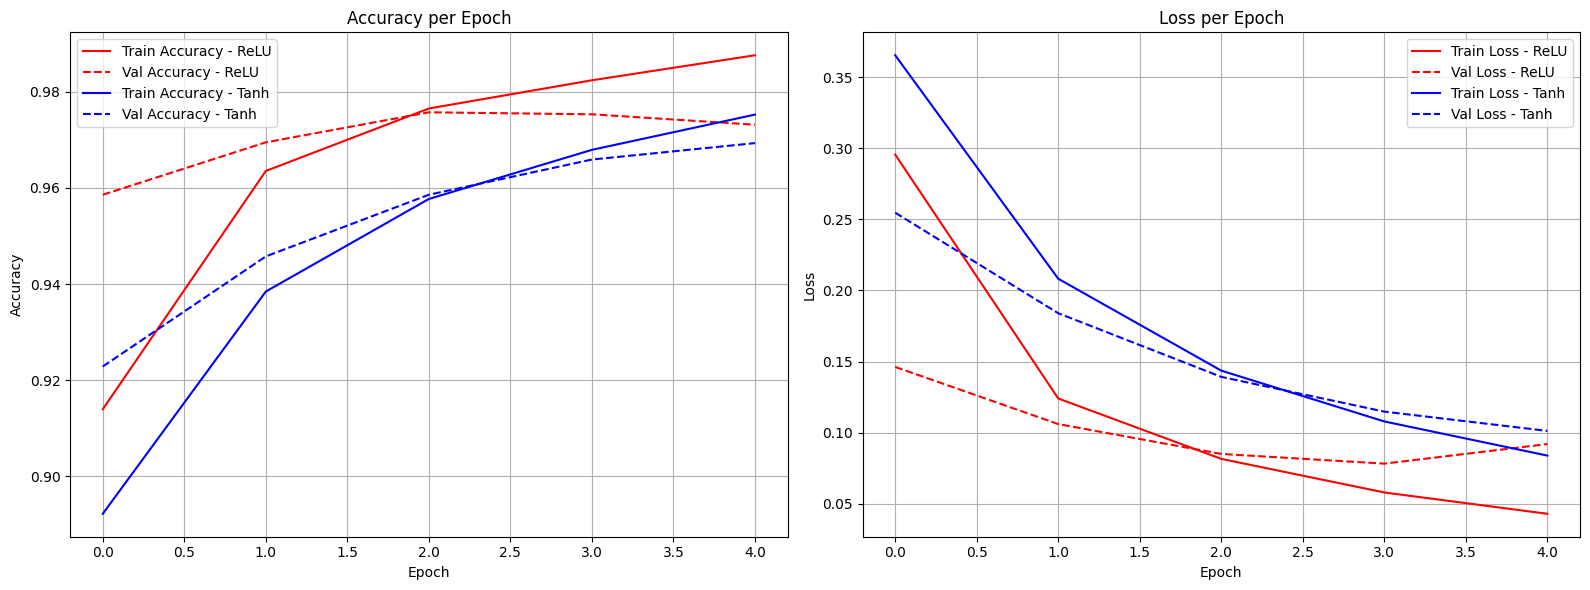

🔍 ReLU:
   Final Test Accuracy: 0.9745
   Final Test Loss: 0.0846

🔍 Tanh:
   Final Test Accuracy: 0.9721
   Final Test Loss: 0.0938


In [3]:
import matplotlib.pyplot as plt
from keras.datasets import mnist
from keras import models, layers
from keras.utils import to_categorical
import numpy as np

# بارگذاری و آماده‌سازی داده‌ها
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
train_images = train_images.reshape((60000, 784)).astype('float32') / 255
test_images = test_images.reshape((10000, 784)).astype('float32') / 255
train_labels = to_categorical(train_labels)
test_labels = to_categorical(test_labels)

# تابع ساخت مدل با اکتیویشن دلخواه
def build_and_train_model(activation_fn):
    model = models.Sequential([
        layers.Dense(512, activation=activation_fn, input_shape=(784,)),
        layers.Dense(10, activation='softmax')
    ])
    model.compile(optimizer='rmsprop',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    history = model.fit(train_images, train_labels,
                        epochs=5, batch_size=128,
                        validation_split=0.2, verbose=0)
    test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=0)
    return history, test_acc, test_loss

# آموزش دو مدل
history_relu, acc_relu, loss_relu = build_and_train_model('relu')
history_tanh, acc_tanh, loss_tanh = build_and_train_model('tanh')

# رسم نمودارها
plt.figure(figsize=(16, 6))

# 📈 Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_relu.history['accuracy'], label='Train Accuracy - ReLU',linestyle='-',color="red")
plt.plot(history_relu.history['val_accuracy'], label='Val Accuracy - ReLU',linestyle='--',color="red")
plt.plot(history_tanh.history['accuracy'], label='Train Accuracy - Tanh',linestyle='-',color="blue")
plt.plot(history_tanh.history['val_accuracy'], label='Val Accuracy - Tanh',linestyle='--',color="blue")
plt.title('Accuracy per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# 📉 Loss
plt.subplot(1, 2, 2)
plt.plot(history_relu.history['loss'], label='Train Loss - ReLU',linestyle='-',color="red")
plt.plot(history_relu.history['val_loss'], label='Val Loss - ReLU',linestyle='--',color="red")
plt.plot(history_tanh.history['loss'], label='Train Loss - Tanh',linestyle='-',color="blue")
plt.plot(history_tanh.history['val_loss'], label='Val Loss - Tanh',linestyle='--',color="blue")
plt.title('Loss per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# نتایج عددی و شروع overfit
print("🔍 ReLU:")
print(f"   Final Test Accuracy: {acc_relu:.4f}")
print(f"   Final Test Loss: {loss_relu:.4f}")

print("\n🔍 Tanh:")
print(f"   Final Test Accuracy: {acc_tanh:.4f}")
print(f"   Final Test Loss: {loss_tanh:.4f}")


MSE vs CrossEntropy

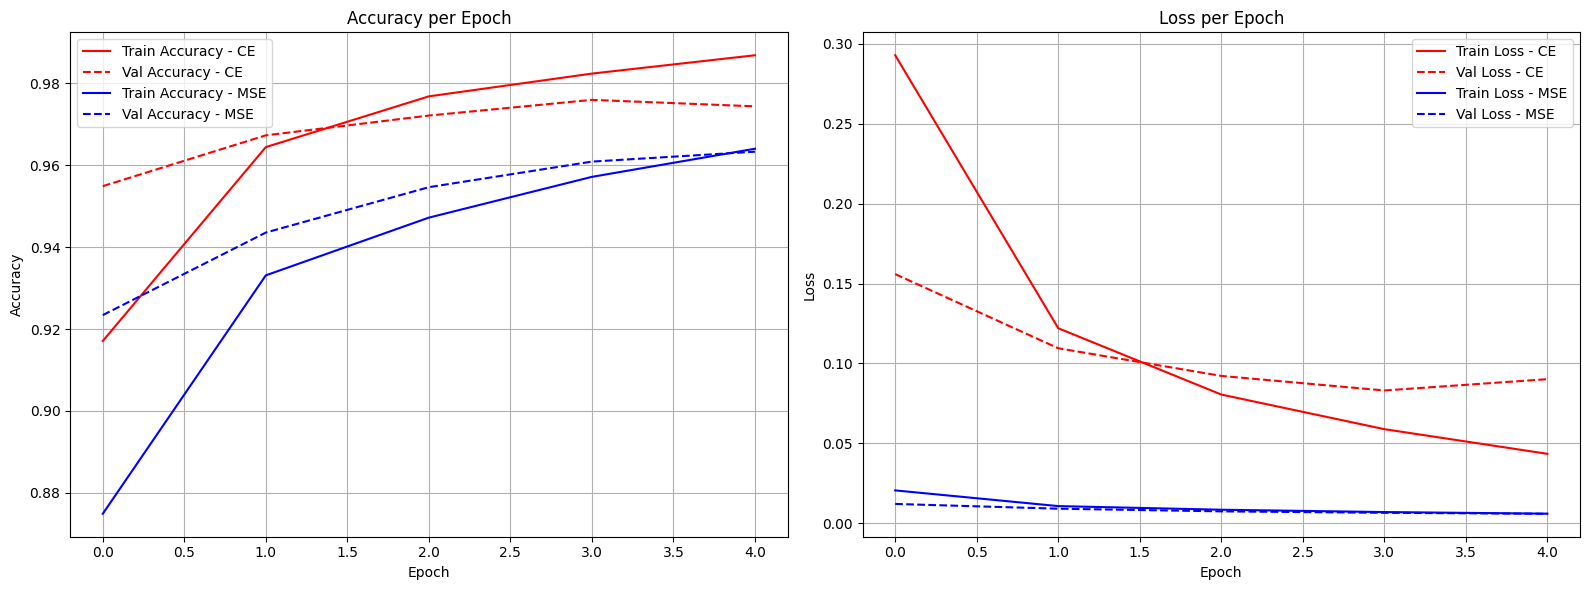

📌 CrossEntropy:
   Final Test Accuracy: 0.9747
   Final Test Loss: 0.0790

📌 MSE:
   Final Test Accuracy: 0.9626
   Final Test Loss: 0.0060


In [ ]:
import matplotlib.pyplot as plt
from keras.datasets import mnist
from keras import models, layers
from keras.utils import to_categorical
import numpy as np

# بارگذاری و آماده‌سازی داده‌ها
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
train_images = train_images.reshape((60000, 784)).astype('float32') / 255
test_images = test_images.reshape((10000, 784)).astype('float32') / 255
train_labels = to_categorical(train_labels)
test_labels = to_categorical(test_labels)

# تابع ساخت و آموزش مدل
def build_and_train_model(loss_fn):
    model = models.Sequential([
        layers.Dense(512, activation='relu', input_shape=(784,)),
        layers.Dense(10, activation='softmax')
    ])
    model.compile(optimizer='rmsprop',
                  loss=loss_fn,
                  metrics=['accuracy'])
    history = model.fit(train_images, train_labels,
                        epochs=5, batch_size=128,
                        validation_split=0.2, verbose=0)
    test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=0)
    return history, test_acc, test_loss

# آموزش دو مدل
history_ce, acc_ce, loss_ce = build_and_train_model('categorical_crossentropy')
history_mse, acc_mse, loss_mse = build_and_train_model('mse')

# رسم نمودارهای مقایسه‌ای
plt.figure(figsize=(16, 6))

# 📈 نمودار دقت
plt.subplot(1, 2, 1)
plt.plot(history_ce.history['accuracy'], label='Train Accuracy - CE', linestyle='-',color="red")
plt.plot(history_ce.history['val_accuracy'], label='Val Accuracy - CE', linestyle='--',color="red")
plt.plot(history_mse.history['accuracy'], label='Train Accuracy - MSE', linestyle='-',color="blue")
plt.plot(history_mse.history['val_accuracy'], label='Val Accuracy - MSE', linestyle='--',color="blue")
plt.title('Accuracy per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# 📉 نمودار Loss
plt.subplot(1, 2, 2)
plt.plot(history_ce.history['loss'], label='Train Loss - CE', linestyle='-',color="red")
plt.plot(history_ce.history['val_loss'], label='Val Loss - CE', linestyle='--',color="red")
plt.plot(history_mse.history['loss'], label='Train Loss - MSE', linestyle='-',color="blue")
plt.plot(history_mse.history['val_loss'], label='Val Loss - MSE', linestyle='--',color="blue")
plt.title('Loss per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# نمایش نتایج عددی
print("📌 CrossEntropy:")
print(f"   Final Test Accuracy: {acc_ce:.4f}")
print(f"   Final Test Loss: {loss_ce:.4f}")
print("\n📌 MSE:")
print(f"   Final Test Accuracy: {acc_mse:.4f}")
print(f"   Final Test Loss: {loss_mse:.4f}")



تغییر تعداد لایه ها

Training with 1 hidden layers...


Training with 3 hidden layers...
Training with 5 hidden layers...


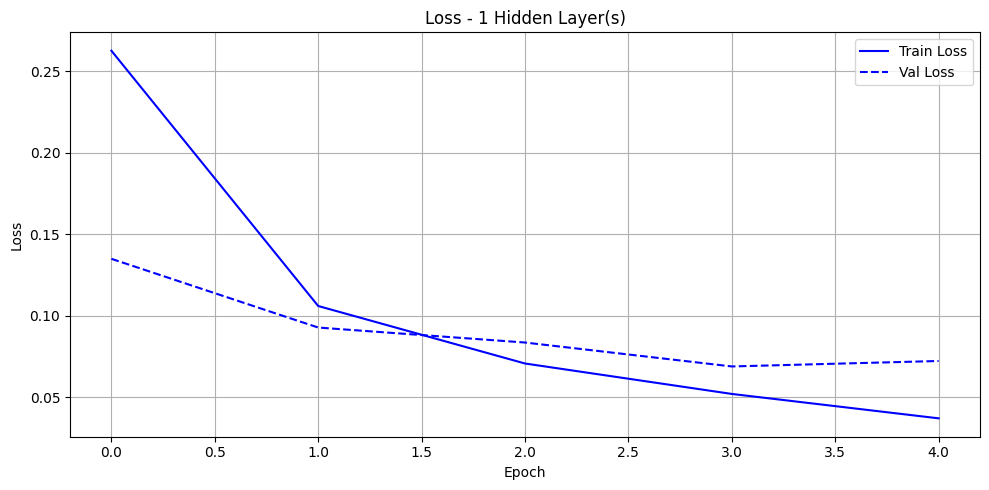

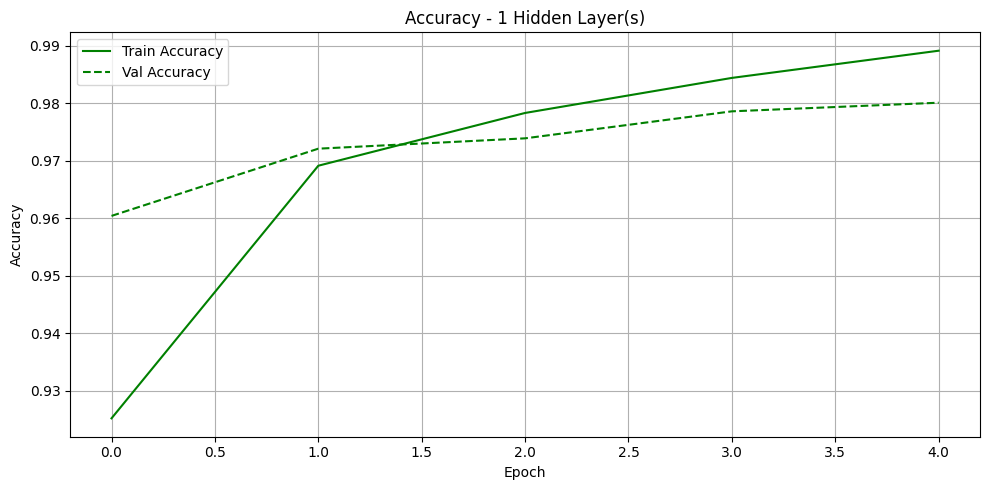

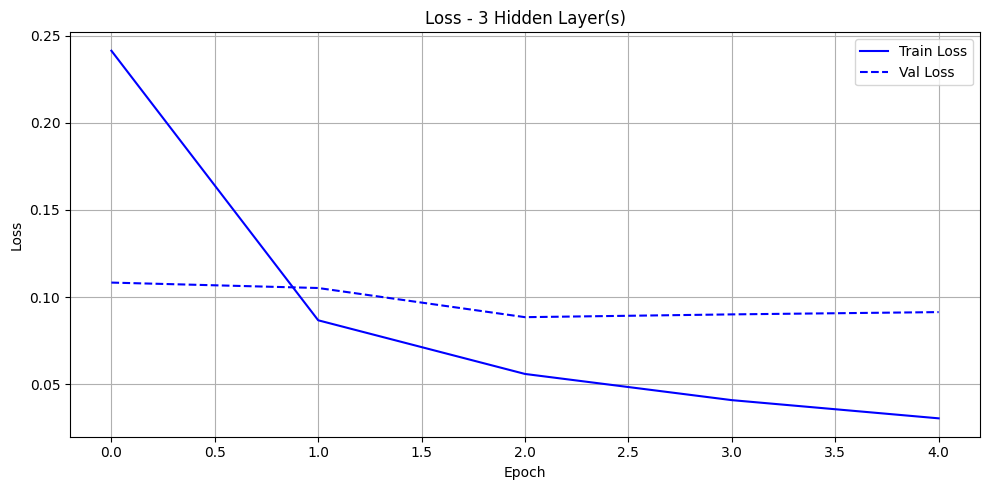

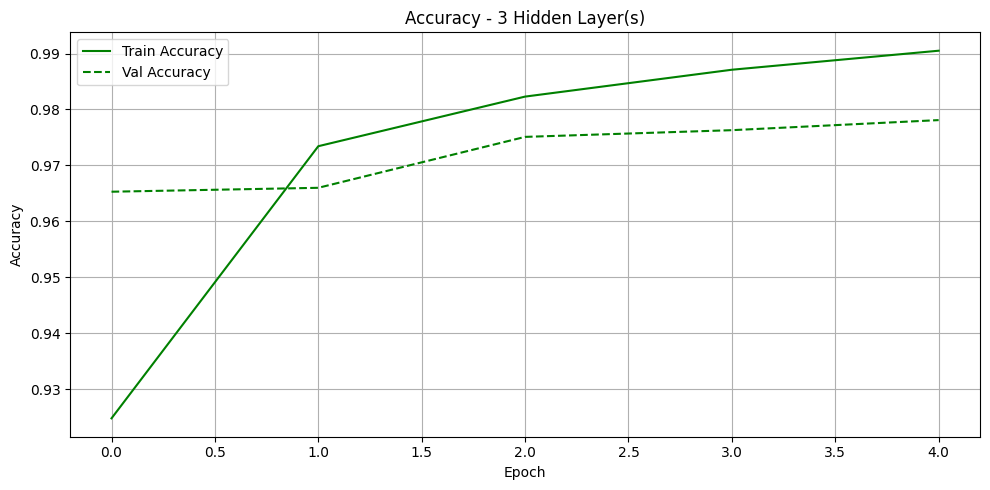

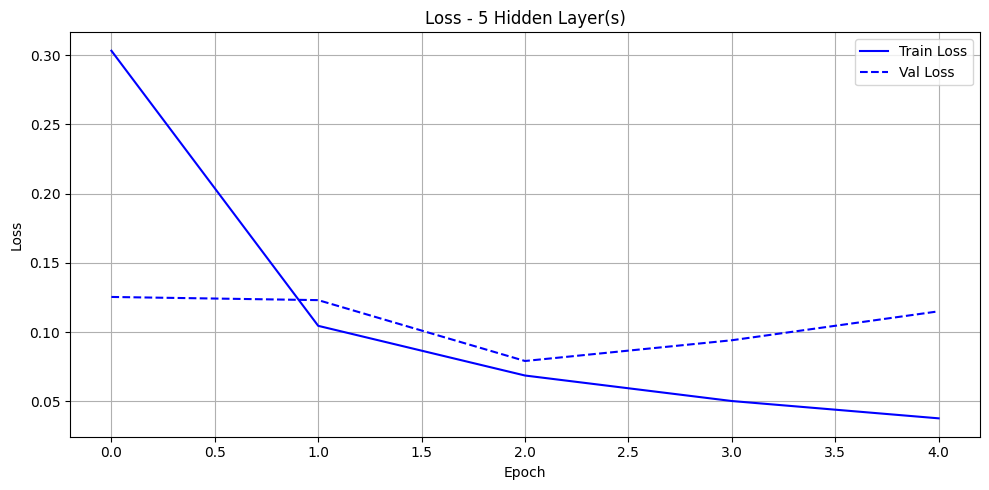

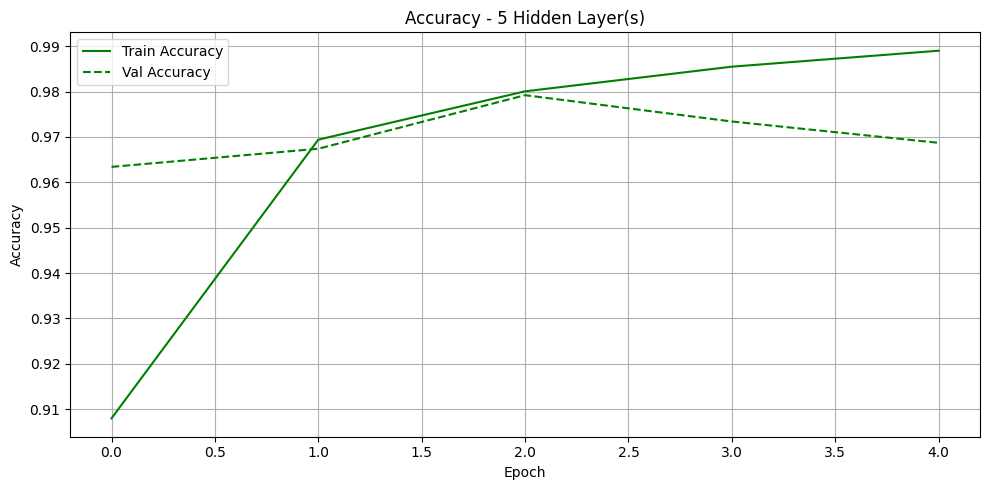

In [7]:
import matplotlib.pyplot as plt
from keras.datasets import mnist
from keras import models, layers
from keras.utils import to_categorical

# بارگذاری داده‌ها
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
train_images = train_images.reshape((60000, 28 * 28)).astype('float32') / 255
test_images = test_images.reshape((10000, 28 * 28)).astype('float32') / 255
train_labels = to_categorical(train_labels)
test_labels = to_categorical(test_labels)

# تابع ساخت مدل با تعداد دلخواه لایه مخفی
def build_model(num_hidden_layers):
    model = models.Sequential()
    model.add(layers.Dense(512, activation='relu', input_shape=(28 * 28,)))
    for _ in range(num_hidden_layers - 1):
        model.add(layers.Dense(512, activation='relu'))
    model.add(layers.Dense(10, activation='softmax'))
    model.compile(optimizer='rmsprop',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

# تعداد لایه‌ها

layer_counts = [1, 3, 5]
results = {}

# آموزش مدل‌ها
for count in layer_counts:
    print(f"Training with {count} hidden layers...")
    model = build_model(count)
    history = model.fit(train_images, train_labels,
                        epochs=5,
                        batch_size=128,
                        validation_data=(test_images, test_labels),
                        verbose=0)
    results[count] = history

# رنگ‌ها و استایل‌ها
import matplotlib.pyplot as plt


for count in layer_counts:
    history = results[count].history
    
    # نمودار Loss
    plt.figure(figsize=(10, 5))
    plt.plot(history['loss'], label='Train Loss',linestyle='-', color='blue')
    plt.plot(history['val_loss'], label='Val Loss',linestyle='--', color='blue')
    plt.title(f"Loss - {count} Hidden Layer(s)")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    
    # نمودار Accuracy
    plt.figure(figsize=(10, 5))
    plt.plot(history['accuracy'], label='Train Accuracy',linestyle='-', color='green')
    plt.plot(history['val_accuracy'], label='Val Accuracy',linestyle='--', color='green')
    plt.title(f"Accuracy - {count} Hidden Layer(s)")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

تغییر تعداد نورون ها 

Training with 128 neurons...
Training with 256 neurons...
Training with 512 neurons...
Training with 1024 neurons...


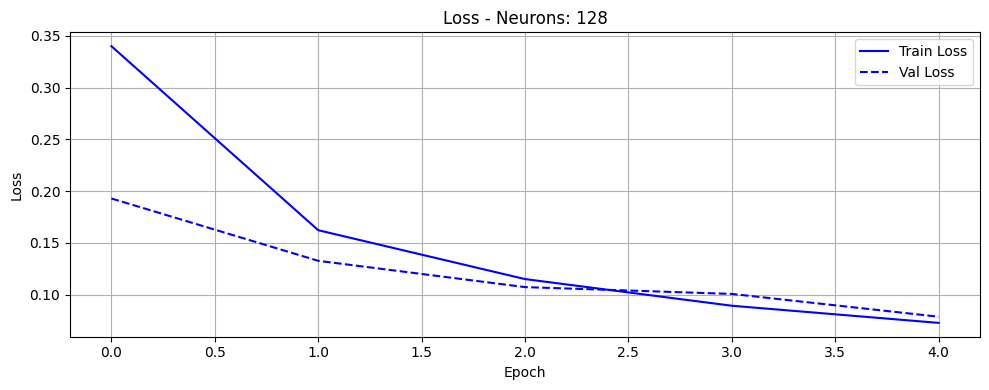

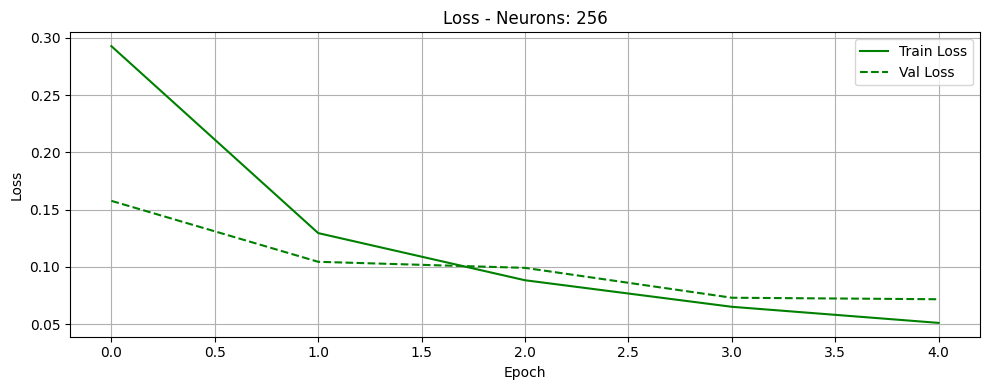

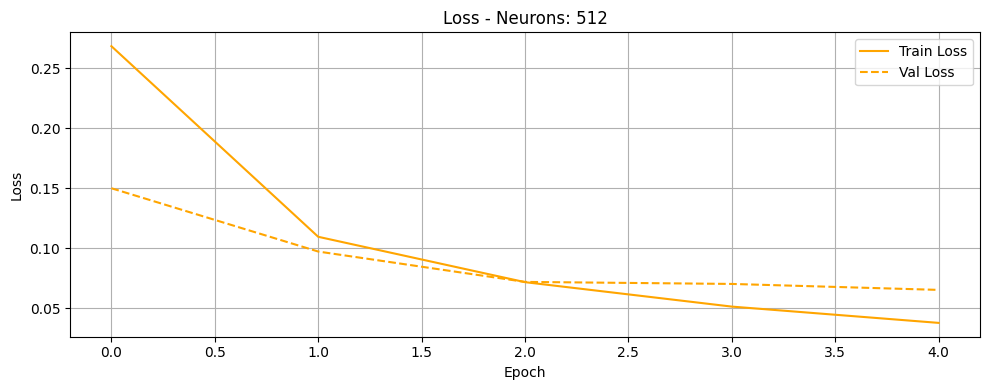

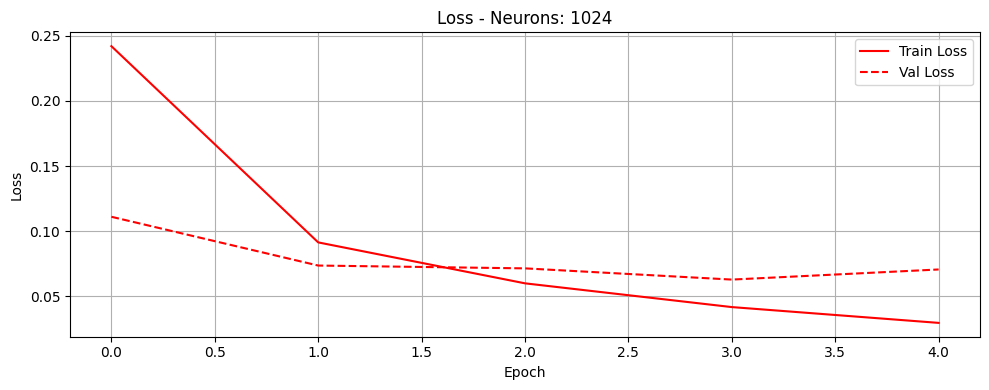

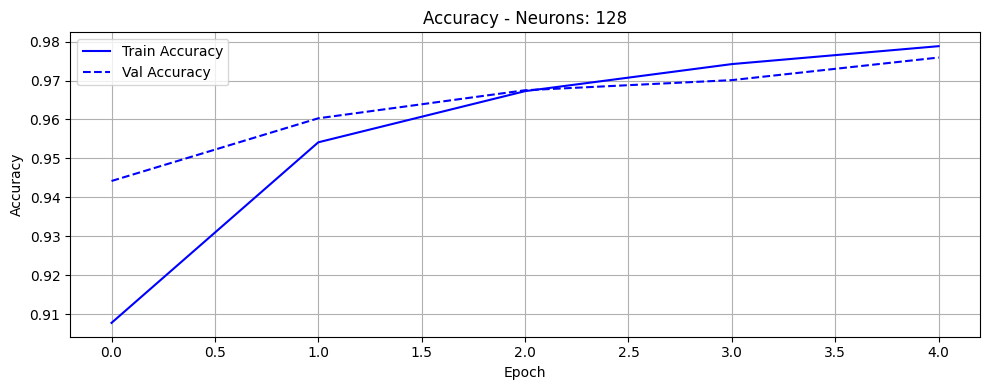

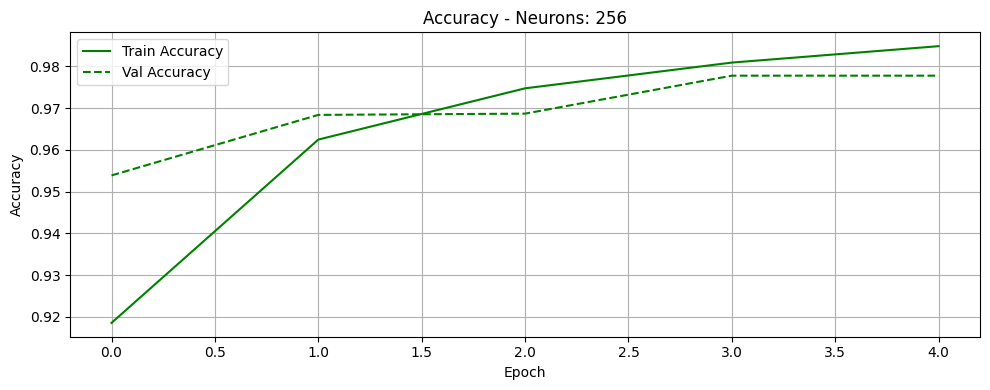

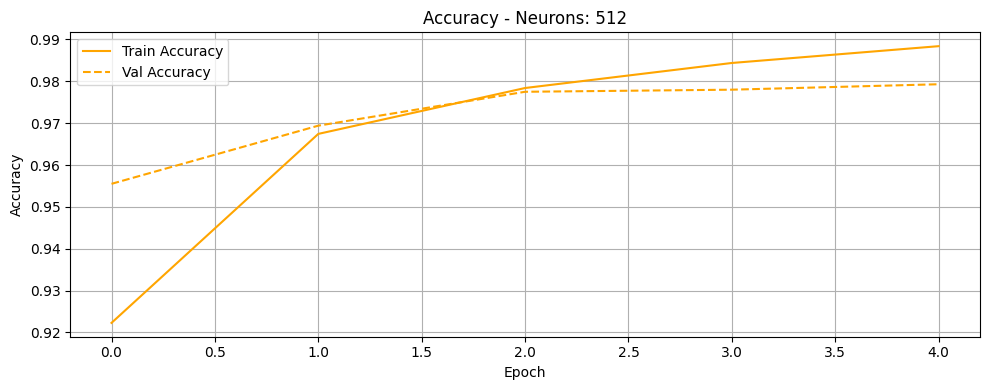

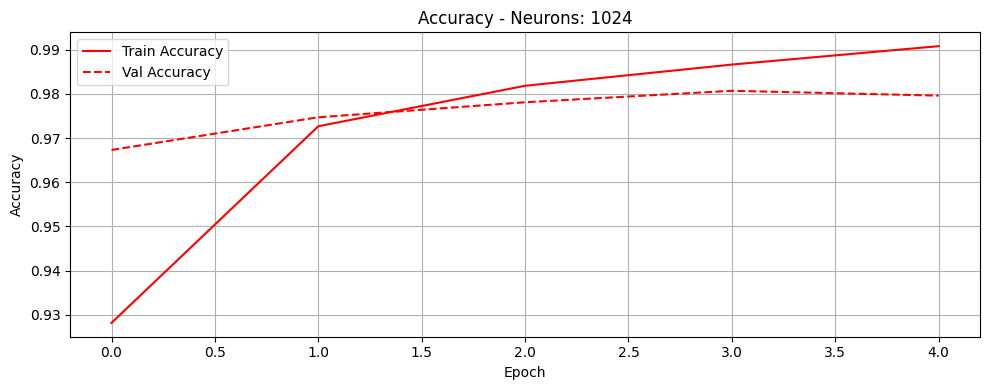

In [9]:
from keras.datasets import mnist
from keras import models
from keras import layers
from keras.utils import to_categorical

def build_model_neurons(num_neurons):
    model = models.Sequential()
    model.add(layers.Dense(num_neurons, activation='relu', input_shape=(28 * 28,)))
    model.add(layers.Dense(10, activation='softmax'))
    model.compile(optimizer='rmsprop',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

# تعداد نورون‌ها
neuron_counts = [128, 256, 512, 1024]
results_neurons = {}

# آموزش مدل‌ها
for neurons in neuron_counts:
    print(f"Training with {neurons} neurons...")
    model = build_model_neurons(neurons)
    history = model.fit(train_images, train_labels,
                        epochs=5,
                        batch_size=128,
                        validation_data=(test_images, test_labels),
                        verbose=0)
    results_neurons[neurons] = history

import matplotlib.pyplot as plt

colors = {128: 'blue', 256: 'green', 512: 'orange', 1024: 'red'}
linestyles = {'train': '-', 'val': '--'}

# نمودارهای Loss
for neurons in neuron_counts:
    history = results_neurons[neurons].history
    plt.figure(figsize=(10, 4))
    plt.plot(history['loss'], label='Train Loss', color=colors[neurons], linestyle=linestyles['train'])
    plt.plot(history['val_loss'], label='Val Loss', color=colors[neurons], linestyle=linestyles['val'])
    plt.title(f"Loss - Neurons: {neurons}")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# نمودارهای Accuracy
for neurons in neuron_counts:
    history = results_neurons[neurons].history
    plt.figure(figsize=(10, 4))
    plt.plot(history['accuracy'], label='Train Accuracy', color=colors[neurons], linestyle=linestyles['train'])
    plt.plot(history['val_accuracy'], label='Val Accuracy', color=colors[neurons], linestyle=linestyles['val'])
    plt.title(f"Accuracy - Neurons: {neurons}")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()